# 6) Equivalent Circuit Fitting and Comparison

This notebook moves from **visualisation** to **physical interpretation**.

Goals:
- Load an impedance dataset (simulated or processed measurement)
- Choose an equivalent circuit model (resistor, capacitor, RC, Randles)
- Compute theoretical impedance using `src/models/equivalent_circuits.py`
- Compare **Nyquist** and **Bode** plots: data vs model
- Write a short physical interpretation of the chosen model


## 1. Setup

Import required modules and ensure the `src/` directory is accessible.

In [25]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure project root and src/ are on the path
project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

from models.equivalent_circuits import (
    Z_resistor,
    Z_capacitor,
    Z_rc_series,
    Z_rc_parallel,
    Z_randles,
    evaluate_model,
)
from visualization.nyquist import nyquist_from_csv
from visualization.bode import bode_from_csv


## 2. Select dataset and model

You can switch between:
- Simulated resistor: `data/simulated/resistor_R100.csv`
- Simulated capacitor: `data/simulated/capacitor_C1uF.csv`
- Simulated RC series: `data/simulated/rc_R100_C1uF.csv`
- Processed measurement: `data/processed/measurement_clean.csv` (example)

And between models:
- `Z_resistor(R)`
- `Z_capacitor(C)`
- `Z_rc_series(R, C)`
- `Z_rc_parallel(R, C)`
- `Z_randles(Rs, Rct, Cdl)`


In [26]:
# --- Choose dataset ---
# Example: RC simulated dataset
data_path = project_root / "data" / "simulated" / "rc_R100_C1uF.csv"

# If you want to use a processed measurement instead, uncomment:
# data_path = project_root / "data" / "processed" / "measurement_clean.csv"

df = pd.read_csv(data_path)
frequencies = df["frequency"].values
Z_data = df["real"].values + 1j * df["imag"].values

print(f"Loaded dataset: {data_path}")
print(f"Number of points: {len(frequencies)}")


Loaded dataset: d:\kero folders\UHA\EIS Project Roadmap\Project\data\simulated\rc_R100_C1uF.csv
Number of points: 400


In [27]:
# --- Choose equivalent circuit model and parameters ---

# Example 1: Series RC model approximating the simulated RC dataset
R_guess = 100.0      # ohms
C_guess = 1e-6       # F
model = Z_rc_series(R_guess, C_guess)

# Example 2: Randles circuit (uncomment to try)
# Rs_guess = 10.0    # solution resistance
# Rct_guess = 200.0  # charge transfer resistance
# Cdl_guess = 1e-5   # double-layer capacitance
# model = Z_randles(Rs_guess, Rct_guess, Cdl_guess)

# Evaluate model on the same frequency vector
Z_model = evaluate_model(model, frequencies)

print("Model evaluated on frequency grid.")


Model evaluated on frequency grid.


## 3. Nyquist comparison: data vs model

We plot the experimental/simulated data and the theoretical model on the same Nyquist diagram.

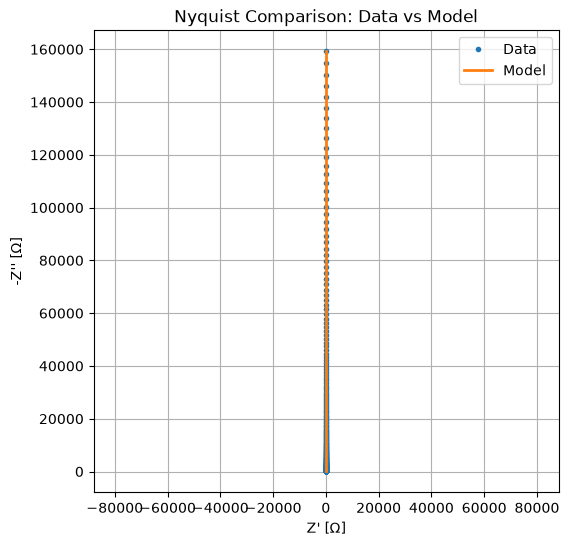

In [28]:
plt.figure(figsize=(6, 6))

# Data
plt.plot(Z_data.real, -Z_data.imag, "o", markersize=3, label="Data")

# Model
plt.plot(Z_model.real, -Z_model.imag, "-", linewidth=2, label="Model")

plt.xlabel("Z' [Ω]")
plt.ylabel("-Z'' [Ω]")
plt.title("Nyquist Comparison: Data vs Model")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.show()


## 4. Bode comparison: magnitude and phase

We compare magnitude and phase as a function of frequency for data and model.

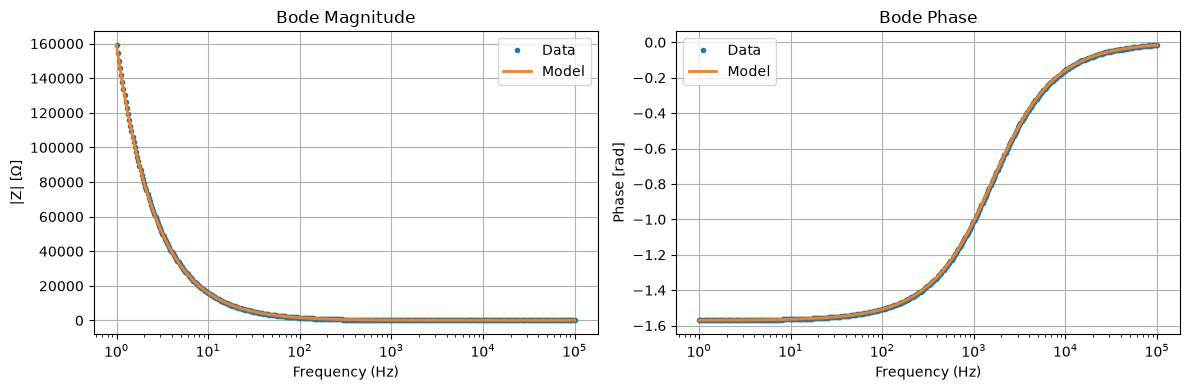

In [29]:
mag_data = np.abs(Z_data)
phase_data = np.angle(Z_data)

mag_model = np.abs(Z_model)
phase_model = np.angle(Z_model)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Magnitude
axes[0].semilogx(frequencies, mag_data, "o", markersize=3, label="Data")
axes[0].semilogx(frequencies, mag_model, "-", linewidth=2, label="Model")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("|Z| [Ω]")
axes[0].set_title("Bode Magnitude")
axes[0].grid(True)
axes[0].legend()

# Phase
axes[1].semilogx(frequencies, phase_data, "o", markersize=3, label="Data")
axes[1].semilogx(frequencies, phase_model, "-", linewidth=2, label="Model")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase [rad]")
axes[1].set_title("Bode Phase")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Simple error metrics (optional)

Compute a basic root-mean-square error (RMSE) between data and model in the complex plane.
This prepares Stage 5 (parameter fitting and quantitative evaluation).

In [30]:
residual = Z_data - Z_model
rmse = np.sqrt(np.mean(np.abs(residual) ** 2))

print(f"RMSE (complex impedance): {rmse:.4f} Ω")


RMSE (complex impedance): 0.1374 Ω


## 6. Physical interpretation (to be written by you)

- Describe why the chosen circuit (e.g. series RC or Randles) makes sense for this dataset.
- Comment on:
  - Low-frequency behaviour (e.g. charge transfer resistance, large semicircle)
  - High-frequency behaviour (e.g. solution resistance, capacitive response)
  - How well the model follows the Nyquist and Bode curves.
- Relate parameters $(R, C, R_s, R_{ct}, C_{dl})$ to physical phenomena in your system.